# Machine learning · Regresión

Regresión lineal implementada a mano con `numpy` y con `scikit-learn`, regresión polinómica, sobreajuste, regularización y métricas. Los datos son sintéticos o el conjunto *diabetes* que trae `scikit-learn`.

## 1. Datos de entrenamiento y de prueba

Generar 100 puntos $y = 3 + 2x + \varepsilon$ con $x \in [0, 10]$ y ruido normal $\varepsilon \sim N(0, 2^2)$. Separarlos en entrenamiento (75 %) y prueba (25 %) con `train_test_split` y dibujarlos.

75 25


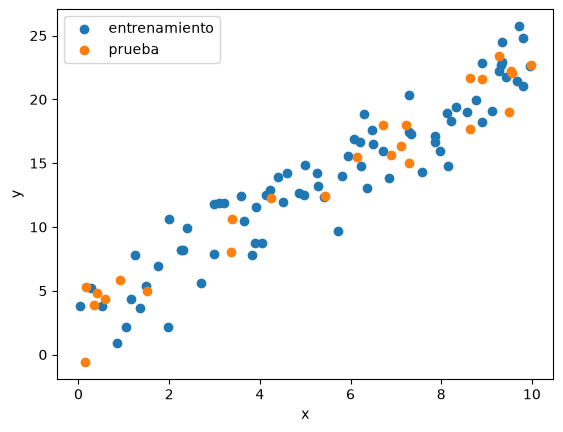

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 100)
y = 3 + 2 * x + rng.normal(0, 2, 100)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)
print(len(x_train), len(x_test))

plt.scatter(x_train, y_train, label="entrenamiento")
plt.scatter(x_test, y_test, label="prueba")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## 2. Mínimos cuadrados

Ajustar la recta con las ecuaciones normales: con la matriz de diseño $X = [\mathbf{1}\ x]$, los coeficientes que minimizan $\lVert X\beta - y \rVert^2$ son

$$\hat\beta = (X^\top X)^{-1} X^\top y.$$

Resolver el sistema con `np.linalg.solve` (sin invertir la matriz) y comprobarlo con `np.linalg.lstsq` y `np.polyfit`.

In [2]:
def diseño(x):
    return np.column_stack([np.ones(len(x)), x])

X_train = diseño(x_train)
beta = np.linalg.solve(X_train.T @ X_train, X_train.T @ y_train)
print("Ordenada y pendiente:", beta)

assert np.allclose(beta, np.linalg.lstsq(X_train, y_train)[0])
assert np.allclose(beta[::-1], np.polyfit(x_train, y_train, 1))

Ordenada y pendiente: [3.0099292  1.97487116]


## 3. Descenso de gradiente

Minimizar el error cuadrático medio $J(\beta) = \frac{1}{n}\lVert X\beta - y\rVert^2$ con descenso de gradiente,

$$\beta \leftarrow \beta - \eta\, \nabla J(\beta), \qquad \nabla J(\beta) = \frac{2}{n} X^\top (X\beta - y),$$

dibujar cómo baja el error y comprobar que se llega a la solución de mínimos cuadrados.

Descenso de gradiente: [3.0099292  1.97487116]
Mínimos cuadrados:     [3.0099292  1.97487116]


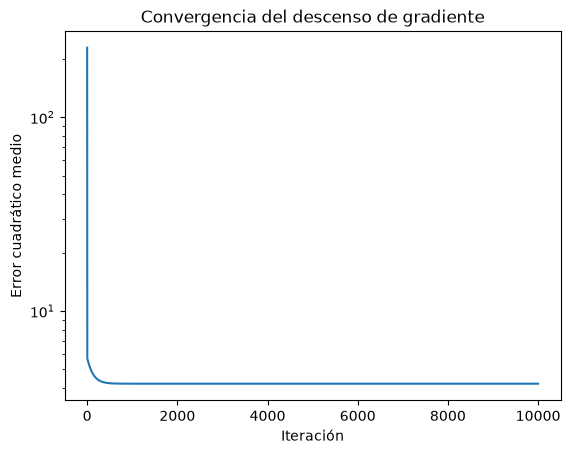

In [3]:
def descenso_gradiente(X, y, eta=0.01, iteraciones=10_000):
    beta = np.zeros(X.shape[1])
    errores = []
    for _ in range(iteraciones):
        residuo = X @ beta - y
        errores.append((residuo ** 2).mean())
        beta -= eta * 2 / len(y) * X.T @ residuo
    return beta, errores

beta_dg, errores = descenso_gradiente(X_train, y_train)
print("Descenso de gradiente:", beta_dg)
print("Mínimos cuadrados:    ", beta)

plt.semilogy(errores)
plt.xlabel("Iteración")
plt.ylabel("Error cuadrático medio")
plt.title("Convergencia del descenso de gradiente")
plt.show()
assert np.allclose(beta_dg, beta, atol=1e-6)

## 4. `LinearRegression`

Ajustar el mismo modelo con `LinearRegression` de `scikit-learn`, comprobar que `intercept_` y `coef_` coinciden con los calculados a mano y dibujar la recta sobre los datos de prueba.

3.009929199951884 [1.97487116]


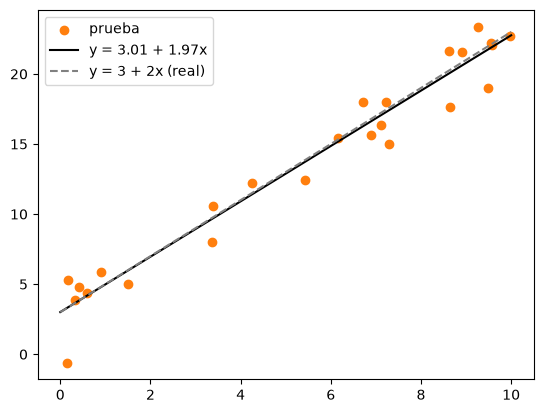

In [4]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression().fit(x_train.reshape(-1, 1), y_train)  # sklearn espera una matriz (n, características)
print(modelo.intercept_, modelo.coef_)
assert np.allclose([modelo.intercept_, *modelo.coef_], beta)

recta = np.linspace(0, 10, 2)
plt.scatter(x_test, y_test, color="tab:orange", label="prueba")
plt.plot(recta, modelo.predict(recta.reshape(-1, 1)), color="black", label=f"y = {beta[0]:.2f} + {beta[1]:.2f}x")
plt.plot(recta, 3 + 2 * recta, "--", color="gray", label="y = 3 + 2x (real)")
plt.legend()
plt.show()

## 5. Métricas

Escribir funciones para el error absoluto medio, la raíz del error cuadrático medio y el coeficiente de determinación,

$$\text{MAE} = \frac{1}{n}\sum |y_i - \hat y_i|, \quad \text{RMSE} = \sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}, \quad R^2 = 1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2},$$

compararlas con las de `sklearn.metrics` y calcularlas en entrenamiento y en prueba.

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

def mae(y, y_pred):
    return np.abs(y - y_pred).mean()

def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())

def r2(y, y_pred):
    return 1 - ((y - y_pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

for nombre, xs, ys in [("entrenamiento", x_train, y_train), ("prueba", x_test, y_test)]:
    pred = modelo.predict(xs.reshape(-1, 1))
    print(f"{nombre:>13}: MAE = {mae(ys, pred):.3f}  RMSE = {rmse(ys, pred):.3f}  R² = {r2(ys, pred):.3f}")
    assert np.isclose(mae(ys, pred), mean_absolute_error(ys, pred))
    assert np.isclose(rmse(ys, pred), root_mean_squared_error(ys, pred))
    assert np.isclose(r2(ys, pred), r2_score(ys, pred))

entrenamiento: MAE = 1.662  RMSE = 2.053  R² = 0.883
       prueba: MAE = 1.241  RMSE = 1.548  R² = 0.952


## 6. Regresión múltiple

Con el conjunto *diabetes* (10 variables, progresión de la enfermedad al cabo de un año), ajustar una regresión lineal múltiple, comprobarla con mínimos cuadrados a mano, dar el $R^2$ de prueba y dibujar los coeficientes y la predicción frente al valor real.

R² de prueba: 0.359  RMSE: 56.4


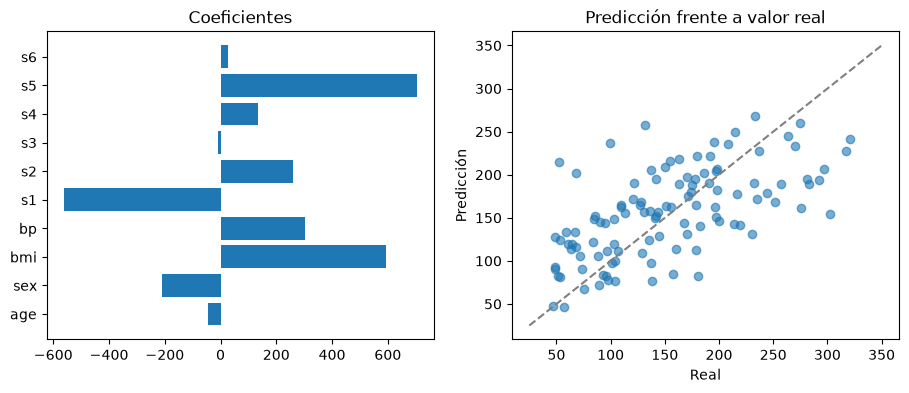

In [6]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(diabetes.data, diabetes.target, test_size=0.25, random_state=0)
multiple = LinearRegression().fit(Xd_train, yd_train)
beta_d = np.linalg.lstsq(np.column_stack([np.ones(len(Xd_train)), Xd_train]), yd_train)[0]
assert np.allclose(beta_d, [multiple.intercept_, *multiple.coef_])

pred = multiple.predict(Xd_test)
print(f"R² de prueba: {r2_score(yd_test, pred):.3f}  RMSE: {root_mean_squared_error(yd_test, pred):.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.barh(diabetes.feature_names, multiple.coef_)
ax1.set_title("Coeficientes")
ax2.scatter(yd_test, pred, alpha=0.6)
ax2.plot([25, 350], [25, 350], "--", color="gray")
ax2.set(xlabel="Real", ylabel="Predicción", title="Predicción frente a valor real")
plt.show()

## 7. Regresión polinómica

Generar 220 puntos de $y = \sin(2\pi x) + \varepsilon$ con $x \in [0, 1]$ y $\varepsilon \sim N(0, 0.3^2)$, entrenar con 20 y dejar 200 para prueba, y ajustar polinomios de grado 1, 3 y 15 con un `Pipeline` de `PolynomialFeatures` y `LinearRegression`. Dibujar las tres curvas.

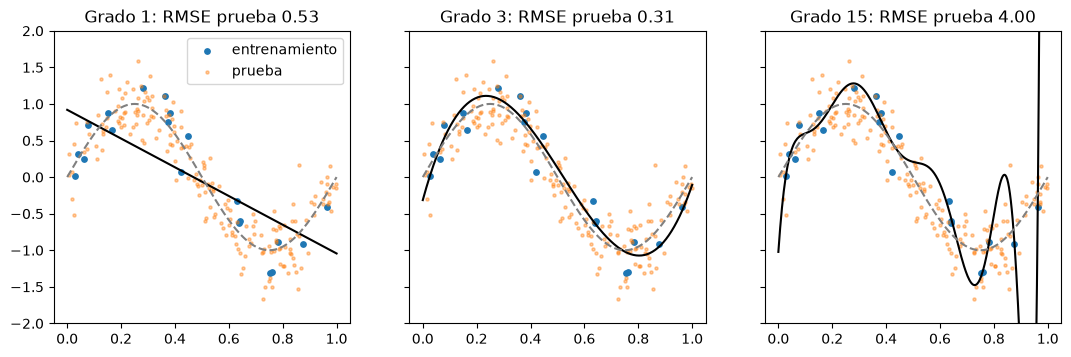

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

rng = np.random.default_rng(1)
xp = rng.uniform(0, 1, 220)
yp = np.sin(2 * np.pi * xp) + rng.normal(0, 0.3, 220)
xp_train, xp_test, yp_train, yp_test = train_test_split(xp.reshape(-1, 1), yp, train_size=20, random_state=0)
malla = np.linspace(0, 1, 300).reshape(-1, 1)

def polinomica(grado):
    return make_pipeline(PolynomialFeatures(grado, include_bias=False), StandardScaler(), LinearRegression())

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, grado in zip(ejes, [1, 3, 15]):
    m = polinomica(grado).fit(xp_train, yp_train)
    ax.scatter(xp_train, yp_train, s=15, label="entrenamiento")
    ax.scatter(xp_test, yp_test, s=5, alpha=0.4, label="prueba")
    ax.plot(malla, m.predict(malla), color="black")
    ax.plot(malla, np.sin(2 * np.pi * malla), "--", color="gray")
    ax.set(title=f"Grado {grado}: RMSE prueba {root_mean_squared_error(yp_test, m.predict(xp_test)):.2f}", ylim=(-2, 2))
ejes[0].legend()
plt.show()

## 8. Sobreajuste

Calcular el RMSE de entrenamiento y de prueba de los polinomios de grado 1 a 15 y dibujarlos. El error de entrenamiento baja al aumentar el grado, pero a partir de cierto punto el de prueba se dispara: el modelo memoriza el ruido de los 20 puntos.

Mejor grado según prueba: 3


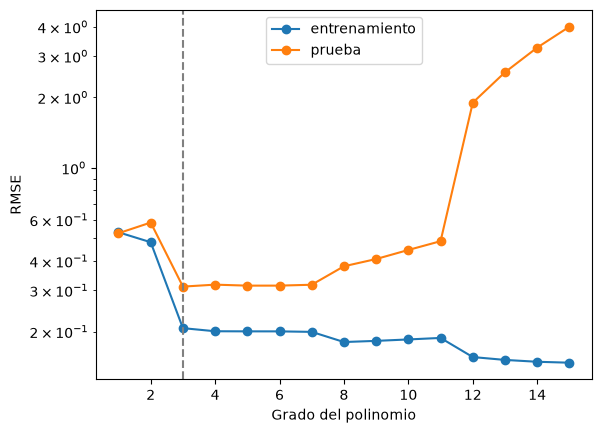

In [8]:
grados = range(1, 16)
err_train, err_test = [], []
for grado in grados:
    m = polinomica(grado).fit(xp_train, yp_train)
    err_train.append(root_mean_squared_error(yp_train, m.predict(xp_train)))
    err_test.append(root_mean_squared_error(yp_test, m.predict(xp_test)))

mejor = grados[int(np.argmin(err_test))]
print("Mejor grado según prueba:", mejor)
plt.plot(grados, err_train, "o-", label="entrenamiento")
plt.plot(grados, err_test, "o-", label="prueba")
plt.axvline(mejor, color="gray", linestyle="--")
plt.yscale("log")
plt.xlabel("Grado del polinomio")
plt.ylabel("RMSE")
plt.legend()
plt.show()

assert err_train[-1] < err_train[0] and err_test[-1] > 5 * min(err_test)

## 9. Regularización: Ridge y Lasso

Ridge y Lasso penalizan coeficientes grandes:

$$\text{Ridge: } \min_\beta \lVert X\beta - y\rVert^2 + \alpha\lVert\beta\rVert_2^2, \qquad \text{Lasso: } \min_\beta \frac{1}{2n}\lVert X\beta - y\rVert^2 + \alpha\lVert\beta\rVert_1.$$

Con el polinomio de grado 15:
- comprobar la solución cerrada de Ridge $\hat\beta = (X^\top X + \alpha I)^{-1}X^\top (y - \bar y)$ con variables centradas,
- dibujar el RMSE de prueba en función de $\alpha$,
- comparar las curvas y contar cuántos coeficientes anula Lasso.

Ridge: mejor alpha = 0.001, RMSE = 0.318


Lasso: mejor alpha = 0.00018, RMSE = 0.316


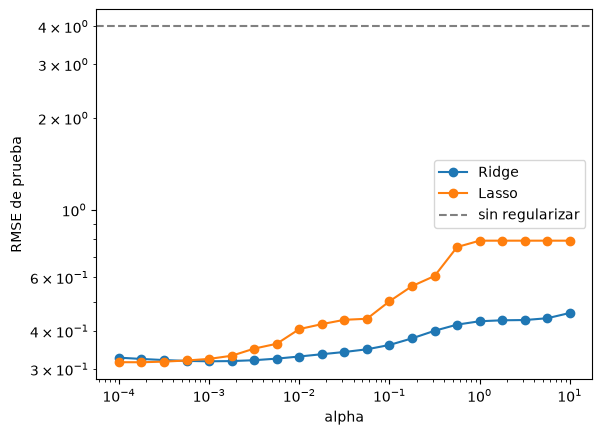

In [9]:
from sklearn.linear_model import Lasso, Ridge

def regularizada(modelo):
    return make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), modelo)

ridge = regularizada(Ridge(alpha=1.0)).fit(xp_train, yp_train)
Z = ridge[:-1].transform(xp_train)  # variables tipificadas: media 0
beta_ridge = np.linalg.solve(Z.T @ Z + 1.0 * np.eye(Z.shape[1]), Z.T @ (yp_train - yp_train.mean()))
assert np.allclose(beta_ridge, ridge[-1].coef_)

alphas = np.logspace(-4, 1, 21)
for nombre, Modelo in [("Ridge", Ridge), ("Lasso", Lasso)]:
    errores = [root_mean_squared_error(yp_test, regularizada(Modelo(alpha=a, max_iter=100_000)).fit(xp_train, yp_train).predict(xp_test))
               for a in alphas]
    plt.semilogx(alphas, errores, "o-", label=nombre)
    print(f"{nombre}: mejor alpha = {alphas[np.argmin(errores)]:.2g}, RMSE = {min(errores):.3f}")
plt.axhline(err_test[-1], color="gray", linestyle="--", label="sin regularizar")
plt.xlabel("alpha")
plt.ylabel("RMSE de prueba")
plt.yscale("log")
plt.legend()
plt.show()

Sin regularizar: 15 coeficientes no nulos, máx |coef| = 2846.4, RMSE prueba 4.001
Ridge (alpha = 0.001): 15 coeficientes no nulos, máx |coef| = 4.4, RMSE prueba 0.318
Lasso (alpha = 0.001): 5 coeficientes no nulos, máx |coef| = 3.9, RMSE prueba 0.324


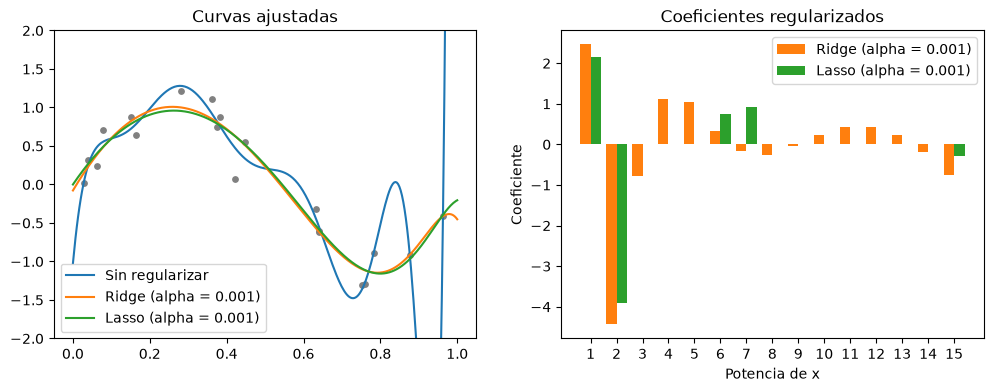

In [10]:
modelos = {
    "Sin regularizar": polinomica(15),
    "Ridge (alpha = 0.001)": regularizada(Ridge(alpha=0.001)),
    "Lasso (alpha = 0.001)": regularizada(Lasso(alpha=0.001, max_iter=100_000)),
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(xp_train, yp_train, s=15, color="gray")
potencias = np.arange(1, 16)
for k, (nombre, m) in enumerate(modelos.items()):
    m.fit(xp_train, yp_train)
    ax1.plot(malla, m.predict(malla), label=nombre)
    if k > 0:
        ax2.bar(potencias + (k - 1.5) * 0.4, m[-1].coef_, 0.4, label=nombre, color=f"C{k}")
    print(f"{nombre}: {np.sum(m[-1].coef_ != 0)} coeficientes no nulos, máx |coef| = {np.abs(m[-1].coef_).max():.1f}, "
          f"RMSE prueba {root_mean_squared_error(yp_test, m.predict(xp_test)):.3f}")
ax1.set(ylim=(-2, 2), title="Curvas ajustadas")
ax2.set(xlabel="Potencia de x", ylabel="Coeficiente", title="Coeficientes regularizados", xticks=potencias)
ax1.legend()
ax2.legend()
plt.show()
assert np.sum(modelos["Lasso (alpha = 0.001)"][-1].coef_ != 0) < 15